# 5 · Toolbox  *(optional, for later)*

Not part of the 90 minutes. Short, self-contained recipes to copy into your own analysis when you need them.
Each section runs on its own (after the setup cell).

| Recipe | When you need it |
|---|---|
| 1. Stacked traces with scale bars | imaging / ephys example traces |
| 2. LFP trace and power spectrum | oscillations |
| 3. Diverging and cyclic colormaps | correlations, z-scores, orientation, phase |
| 4. Is my palette color-blind safe? | choosing colors for a new figure |
| 5. More style variants: dark slides, boxed axes | talks with dark background, physics-style journals |
| 6. Check a style file for typos | after editing `my_style.mplstyle` |
| 7. Is the text in my PDF editable? | before sending a figure to a journal or to Illustrator |
| 8. Huge scatter plots: `rasterized=True` | PDFs that are slow to open |
| 9. Two more code habits | narrow panels, condition-vs-condition scatter |

In [1]:
import shutil
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

import neurodata

plt.style.use(["default", "my_style.mplstyle"])   # your style file from notebook 2
mm = 1 / 25.4
Path("output").mkdir(exist_ok=True)
Path("my_styles").mkdir(exist_ok=True)

## 1. Stacked traces with scale bars

Example traces are usually shown without axes, with **scale bars** instead.

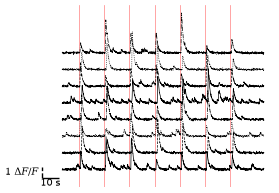

In [2]:
def add_scalebar(ax, x, y, dx, dy, xlabel, ylabel, color="black"):
    """L-shaped scale bar with its corner at (x, y), in data units. Hides the axes."""
    kw = dict(color=color, linewidth=1, solid_capstyle="butt", clip_on=False)
    ax.plot([x, x + dx], [y, y], **kw)
    ax.plot([x, x], [y, y + dy], **kw)
    ax.text(x + dx / 2, y, xlabel, ha="center", va="top")
    ax.text(x, y + dy / 2, ylabel + " ", ha="right", va="center")
    ax.spines[:].set_visible(False)
    ax.set(xticks=[], yticks=[])


t_ca, dff, stim_times = neurodata.calcium_imaging()
responsive = np.argsort(dff.max(axis=1))[-8:]

fig, ax = plt.subplots(figsize=(80 * mm, 60 * mm))
for k, i in enumerate(responsive):
    ax.plot(t_ca, dff[i] + 1.5 * k, color="black", linewidth=0.5)
for s in stim_times:
    ax.axvline(s, color="C1", linewidth=0.5, alpha=0.5, zorder=0)
add_scalebar(ax, x=-12, y=-0.8, dx=10, dy=1, xlabel="10 s", ylabel=r"1 $\Delta F/F$")
plt.show()

## 2. LFP trace and power spectrum

Power spectra go on **log–log** axes. `scipy.signal.welch` estimates the spectrum.

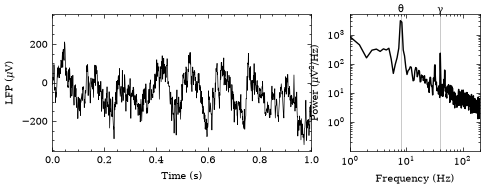

In [3]:
from scipy import signal

t_lfp, x_lfp = neurodata.lfp()
freqs, power = signal.welch(x_lfp, fs=1000, nperseg=2048)

fig, (ax_t, ax_f) = plt.subplots(1, 2, figsize=(140 * mm, 45 * mm), width_ratios=[2, 1])
ax_t.plot(t_lfp, x_lfp, color="black", linewidth=0.5)
ax_t.set(xlim=(0, 1), xlabel="Time (s)", ylabel=r"LFP ($\mu$V)")
ax_f.loglog(freqs[1:], power[1:], color="black")
ax_f.set(xlim=(1, 200), xlabel="Frequency (Hz)", ylabel=r"Power ($\mu$V$^2$/Hz)")
for f0, name in [(8, "θ"), (40, "γ")]:
    ax_f.axvline(f0, color="0.7", linewidth=0.5, zorder=0)
    ax_f.text(f0, 1.0, name, transform=ax_f.get_xaxis_transform(), ha="center", va="bottom")
plt.show()

## 3. Diverging and cyclic colormaps

**Diverging** (correlations, z-scores, change from baseline): white must be at **zero**, so make the limits
symmetric. **Cyclic** (orientation, phase): 0° and 180° are the same orientation, so they should be the same color.

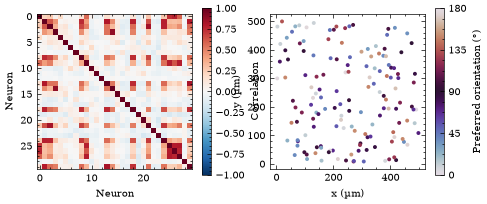

In [4]:
corr = np.corrcoef(dff[:30])

rng = np.random.default_rng(1)
x_pos, y_pos = rng.uniform(0, 500, (2, 150))
preferred = rng.uniform(0, 180, 150)

fig, (ax_c, ax_o) = plt.subplots(1, 2, figsize=(140 * mm, 55 * mm))
im = ax_c.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1, aspect="equal")
fig.colorbar(im, ax=ax_c, label="Correlation")
ax_c.set(xlabel="Neuron", ylabel="Neuron")

sc = ax_o.scatter(x_pos, y_pos, c=preferred, cmap="twilight", vmin=0, vmax=180, s=8)
fig.colorbar(sc, ax=ax_o, label="Preferred orientation (°)", ticks=[0, 45, 90, 135, 180])
ax_o.set(xlabel="x (µm)", ylabel="y (µm)", aspect="equal")
plt.show()

## 4. Is my palette color-blind safe?

Simulates deuteranopia (the most common type) for a list of colors. For whole figures, upload a PNG to
[Coblis](https://www.color-blindness.com/coblis-color-blindness-simulator/).

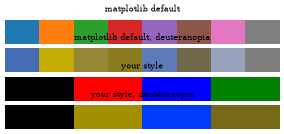

In [5]:
from matplotlib.colors import to_rgb

DEUTAN = np.array([[0.367322, 0.860646, -0.227968],
                   [0.280085, 0.672501, 0.047413],
                   [-0.011820, 0.042940, 0.968881]])


def simulate_deuteranopia(colors):
    rgb = np.array([to_rgb(c) for c in colors])
    linear = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    sim = np.clip(linear @ DEUTAN.T, 0, 1)
    return np.where(sim <= 0.0031308, 12.92 * sim, 1.055 * sim ** (1 / 2.4) - 0.055)


def show_palettes(palettes):
    fig, axes = plt.subplots(len(palettes), 1, figsize=(90 * mm, 9 * mm * len(palettes)))
    for ax, (title, colors) in zip(axes, palettes.items()):
        ax.imshow(np.array([to_rgb(c) for c in colors])[None], aspect="auto")
        ax.set_title(title, fontsize=6)
        ax.set_axis_off()
    plt.show()


tab10 = [plt.get_cmap("tab10")(i) for i in range(8)]
mine = plt.rcParams["axes.prop_cycle"].by_key()["color"]
show_palettes({"matplotlib default": tab10, "matplotlib default, deuteranopia": simulate_deuteranopia(tab10),
               "your style": mine, "your style, deuteranopia": simulate_deuteranopia(mine)})

## 5. More style variants

Variants contain **only what changes** and go on top of your `my_style.mplstyle`.

* `neuro-dark`: light text on a dark background, for dark slide templates
* `neuro-boxed`: closed box, small ticks pointing in, minor ticks. Common in physics and engineering
  journals (it's the look of the popular SciencePlots package). On category axes and heatmaps, turn
  the minor ticks off with `ax.minorticks_off()`.

In [6]:
%%writefile my_styles/neuro-dark.mplstyle
# neuro-dark: dark slides. Use: plt.style.use(["my_style.mplstyle", "my_styles/neuro-dark.mplstyle"])
figure.facecolor: 111111
axes.facecolor: 111111
savefig.facecolor: 111111
text.color: EEEEEE
axes.labelcolor: EEEEEE
axes.edgecolor: EEEEEE
xtick.color: EEEEEE
ytick.color: EEEEEE
# Okabe-Ito with white instead of black
axes.prop_cycle: cycler('color', ['56B4E9', 'E69F00', '009E73', 'CC79A7', 'D55E00', '0072B2', 'F0E442', 'FFFFFF'])
image.cmap: magma
boxplot.medianprops.color: EEEEEE

Writing my_styles/neuro-dark.mplstyle


In [7]:
%%writefile my_styles/neuro-boxed.mplstyle
# neuro-boxed: closed box, ticks in, minor ticks. Use: plt.style.use(["my_style.mplstyle", "my_styles/neuro-boxed.mplstyle"])
axes.spines.top: True
axes.spines.right: True
xtick.direction: in
ytick.direction: in
xtick.top: True
ytick.right: True
xtick.minor.visible: True
ytick.minor.visible: True
xtick.minor.size: 1.5
ytick.minor.size: 1.5
xtick.minor.width: 0.5
ytick.minor.width: 0.5

Writing my_styles/neuro-boxed.mplstyle


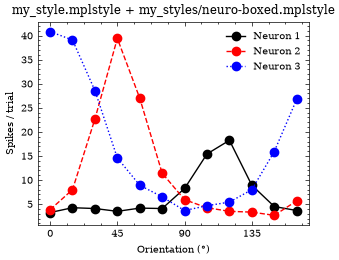

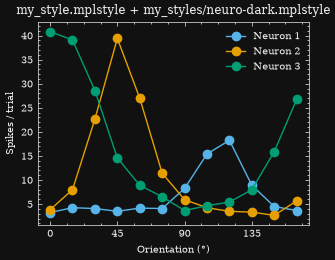

In [8]:
oris, responses = neurodata.orientation_tuning(n_neurons=3)
mean = responses.mean(axis=2)

for variant in ["my_styles/neuro-boxed.mplstyle", "my_styles/neuro-dark.mplstyle"]:
    styles = ["my_style.mplstyle", variant]
    with plt.style.context(["default"] + styles):
        fig, ax = plt.subplots()
        for i in range(3):
            ax.plot(oris, mean[i], marker="o", label=f"Neuron {i + 1}")
        ax.set(xlabel="Orientation (°)", ylabel="Spikes / trial", xticks=[0, 45, 90, 135], title=" + ".join(styles))
        ax.legend()
        plt.show()

**Use your style by name, in every project.** Copy it into matplotlib's style folder once; from then on
`plt.style.use("my_style")` works in any notebook on this computer, without the file next to it.

In [9]:
stylelib = Path(mpl.get_configdir()) / "stylelib"
stylelib.mkdir(parents=True, exist_ok=True)
shutil.copy("my_style.mplstyle", stylelib)
plt.style.reload_library()
print([s for s in plt.style.available if s.startswith("my_")])

['my_style']


*About LaTeX:* `text.usetex: True` typesets all text with a real LaTeX installation. It needs LaTeX installed,
is slow, and gives a serif font, while most biology journals want Arial. `mathtext.default: regular`
(add it to your style) handles $\mu$, $\Delta F/F$ and $x^2$ without it.

## 6. Check a style file for typos

matplotlib only prints a warning for a misspelled key and carries on. This reports unknown keys and keys
that are set twice (the later one wins, usually not what you meant).

In [10]:
def check_style(path):
    """Report unknown and duplicated keys in a .mplstyle file."""
    seen, problems = {}, 0
    for n, line in enumerate(Path(path).read_text().splitlines(), start=1):
        line = line.split("#")[0].strip()
        if not line:
            continue
        key = line.split(":")[0].strip()
        if key not in mpl.rcParams:
            print(f"line {n}: unknown key '{key}'")
            problems += 1
        if key in seen:
            print(f"line {n}: '{key}' was already set on line {seen[key]} (this one wins)")
            problems += 1
        seen[key] = n
    print(f"{path}: {len(seen)} settings, {problems} problems")


check_style("my_style.mplstyle")
for f in sorted(Path("my_styles").glob("*.mplstyle")):
    check_style(f)

my_style.mplstyle: 41 settings, 0 problems
my_styles\neuro-boxed.mplstyle: 12 settings, 0 problems
my_styles\neuro-dark.mplstyle: 11 settings, 0 problems


## 7. Is the text in my PDF editable?

With `pdf.fonttype: 42` the fonts are embedded as TrueType (editable). The default, Type 3, is hard to edit
and rejected by some journals. Look inside the file:

In [11]:
def pdf_font_types(path):
    """Count the font types embedded in a PDF file."""
    data = Path(path).read_bytes()
    return {"Type 3 (hard to edit)": data.count(b"/Type3"),
            "TrueType (editable)": data.count(b"/TrueType") + data.count(b"/CIDFontType2")}


for fonttype in [3, 42]:
    with mpl.rc_context({"pdf.fonttype": fonttype}):
        fig, ax = plt.subplots()
        ax.plot(oris, mean[0])
        ax.set(xlabel="Orientation (°)", ylabel="Spikes / trial")
        fig.savefig(f"output/fonttype_{fonttype}.pdf")
        plt.close(fig)
    print(f"pdf.fonttype {fonttype}:", pdf_font_types(f"output/fonttype_{fonttype}.pdf"))

pdf.fonttype 3: {'Type 3 (hard to edit)': 1, 'TrueType (editable)': 0}
pdf.fonttype 42: {'Type 3 (hard to edit)': 0, 'TrueType (editable)': 1}


## 8. Huge scatter plots: `rasterized=True`

50,000 points are 50,000 vector objects in a PDF: huge and slow to open. Rasterize just that artist; axes
and text stay vector.

In [12]:
xy = np.random.default_rng(0).normal(size=(2, 50_000))
for rasterized in [False, True]:
    fig, ax = plt.subplots(figsize=(60 * mm, 60 * mm))
    ax.scatter(xy[0], xy[1], s=1, alpha=0.3, rasterized=rasterized)
    fig.savefig(f"output/scatter_{rasterized}.pdf")
    plt.close(fig)
    print(f"rasterized={rasterized}: {Path(f'output/scatter_{rasterized}.pdf').stat().st_size / 1000:,.0f} kB")

rasterized=False: 752 kB
rasterized=True: 21 kB


## 9. Two more code habits

* **Fewer ticks on narrow panels:** `ax.locator_params(axis="x", nbins=3)` asks for about 3 intervals.
* **Condition vs condition:** for paired data with many cells, scatter one condition against the other
  with the identity line. Points below it decreased. Use **equal axes**, so the line is really at 45°.

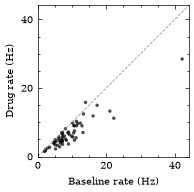

In [13]:
rng = np.random.default_rng(3)
before = rng.lognormal(np.log(8), 0.5, 60)
after = before * rng.normal(0.75, 0.15, 60)
lim = (0, max(before.max(), after.max()) * 1.05)

fig, ax = plt.subplots(figsize=(50 * mm, 50 * mm))
ax.scatter(before, after, s=6, alpha=0.7)
ax.axline((0, 0), slope=1, color="0.6", linestyle="--", linewidth=0.6)
ax.set(xlabel="Baseline rate (Hz)", ylabel="Drug rate (Hz)", xlim=lim, ylim=lim, aspect="equal")
ax.locator_params(nbins=4)
plt.show()